# 01 — Yield curve and swap pricing

**Question 1 of the project:** what is an interest-rate swap worth today?

This notebook only calls code from `src/`; nothing is computed here that the tests do not cover.

1. Bootstrap a zero curve from the US Treasury par-yield snapshot.
2. Price one swap leg by leg (cash-flow table).
3. Value the synthetic 10-swap portfolio and aggregate it by netting set.
4. Check the par-swap and payer/receiver relationships.

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
%matplotlib inline

from src.config import CURVE_FILE, PORTFOLIO_FILE, VALUATION_DATE
from src.curves import curve_table, load_par_yields, load_treasury_curve
from src.instruments import load_portfolio, portfolio_to_frame
from src.plotting import plot_curve
from src.swap_pricer import cashflow_table, netting_set_summary, par_rate, price_portfolio, swap_mtm

pd.set_option('display.float_format', '{:,.6f}'.format)

## 1. Curve

Treasury quotes are **par yields** (semiannual, bond-equivalent). Each quote is treated as a bond priced at par,
$1 = y\sum_k \tau_k P(0,T_k) + P(0,T_n)$, and the discount factors are solved one coupon date at a time.
Between nodes the curve is linear in $\log P$, so forward rates are constant between nodes.

In [2]:
par_yields = load_par_yields(CURVE_FILE)
curve = load_treasury_curve(CURVE_FILE)
print(f'Valuation date: {VALUATION_DATE}, {len(curve.times)} bootstrapped nodes')
par_yields[['tenor_label', 'tenor_years', 'par_yield_pct']]

Valuation date: 2026-10-02, 64 bootstrapped nodes


,tenor_label,tenor_years,par_yield_pct
0,1 Mo,0.083333,4.040000
1,2 Mo,0.166667,4.110000
2,3 Mo,0.250000,4.190000
3,4 Mo,0.333333,4.260000
4,6 Mo,0.500000,4.270000
5,1 Yr,1.000000,4.460000
6,2 Yr,2.000000,4.830000
7,3 Yr,3.000000,4.960000
8,5 Yr,5.000000,5.060000
9,7 Yr,7.000000,5.170000


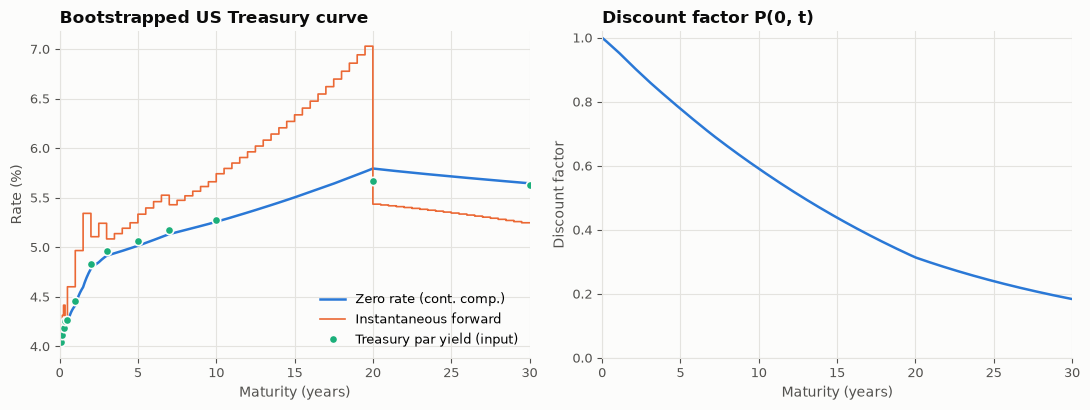

In [3]:
fig = plot_curve(curve, par_yields)

In [4]:
curve_table(curve).iloc[::4]

,time,zero_rate,discount_factor,forward_rate_to_next_node
0,0.083333,0.040332,0.996645,0.041588
4,0.500000,0.042251,0.979096,0.046011
8,2.500000,0.048483,0.885851,0.052420
12,4.500000,0.049885,0.798928,0.052471
16,6.500000,0.051027,0.717721,0.055254
20,8.500000,0.051931,0.643128,0.055656
24,10.500000,0.052792,0.574464,0.057954
28,12.500000,0.053751,0.510743,0.060214
32,14.500000,0.054768,0.451969,0.062701
36,16.500000,0.055853,0.397894,0.065467


The forward curve's sawtooth shape and its jump at 20Y come from linearly interpolating par yields, plus the real 20Y Treasury anomaly (the 20Y yields more than the 30Y). Every trade in the book matures within 10Y.

## 2. One swap, leg by leg

Signs are from our perspective. A payer swap pays fixed (negative cash flows) and receives floating at the forward rate
$F_j = (P(S_j)/P(T_j)-1)/\tau_j$. The `pv` column sums to the mark-to-market.

In [5]:
portfolio = load_portfolio(PORTFOLIO_FILE)
example = portfolio[0]
flows = cashflow_table(example, curve)
print(example)
print(f"Sum of PVs = {flows['pv'].sum():,.2f}   MtM = {swap_mtm(example, curve):,.2f}")
flows.head(9)

Swap(trade_id='A1', counterparty_id='CPTY_A', netting_set_id='NS_A', notional=50000000.0, fixed_rate=0.0478, direction='payer', start=0.0, maturity=10.0, fixed_freq=2, float_freq=4)
Sum of PVs = 1,935,625.72   MtM = 1,935,625.72


,leg,accrual_start,pay_time,accrual,rate,cashflow,discount_factor,pv
0,float,0.000000,0.250000,0.250000,0.041900,"523,750.000000",0.989634,"518,320.591801"
1,fixed,0.000000,0.500000,0.500000,0.047800,"-1,195,000.000000",0.979096,"-1,170,020.071474"
2,float,0.250000,0.500000,0.250000,0.043049,"538,113.263564",0.979096,"526,864.702173"
3,float,0.500000,0.750000,0.250000,0.046277,"578,456.592285",0.967899,"559,887.295872"
4,fixed,0.500000,1.000000,0.500000,0.047800,"-1,195,000.000000",0.956829,"-1,143,410.498294"
5,float,0.750000,1.000000,0.250000,0.046277,"578,456.592285",0.956829,"553,483.966884"
6,float,1.000000,1.250000,0.250000,0.049975,"624,687.248130",0.945022,"590,343.195696"
7,fixed,1.000000,1.500000,0.500000,0.047800,"-1,195,000.000000",0.933361,"-1,115,366.195135"
8,float,1.250000,1.500000,0.250000,0.049975,"624,687.248130",0.933361,"583,058.610122"


## 3. Portfolio valuation and netting sets

In [6]:
portfolio_to_frame(portfolio)

,trade_id,counterparty_id,netting_set_id,notional,fixed_rate,direction,start,maturity,fixed_freq,float_freq
0,A1,CPTY_A,NS_A,"50,000,000.000000",0.047800,payer,0.000000,10.000000,2,4
1,A2,CPTY_A,NS_A,"30,000,000.000000",0.054200,receiver,0.000000,7.000000,2,4
2,A3,CPTY_A,NS_A,"25,000,000.000000",0.052700,payer,1.000000,6.000000,2,4
3,A4,CPTY_A,NS_A,"40,000,000.000000",0.049800,receiver,0.000000,10.000000,2,4
4,A5,CPTY_A,NS_A,"20,000,000.000000",0.053600,payer,0.000000,3.000000,2,4
5,A6,CPTY_A,NS_A,"15,000,000.000000",0.054300,receiver,0.000000,2.000000,2,4
6,B1,CPTY_B,NS_B,"30,000,000.000000",0.048100,payer,0.000000,5.000000,2,4
7,B2,CPTY_B,NS_B,"20,000,000.000000",0.054100,payer,0.000000,8.000000,2,4
8,B3,CPTY_B,NS_B,"25,000,000.000000",0.046100,payer,0.000000,4.000000,2,4
9,B4,CPTY_B,NS_B,"10,000,000.000000",0.052600,receiver,0.000000,3.000000,2,4


In [7]:
valuation = price_portfolio(portfolio, curve)
valuation[['trade_id', 'netting_set_id', 'direction', 'notional', 'fixed_rate', 'par_rate', 'mtm']]

,trade_id,netting_set_id,direction,notional,fixed_rate,par_rate,mtm
0,A1,NS_A,payer,"50,000,000.000000",0.047800,0.052800,"1,935,625.721971"
1,A2,NS_A,receiver,"30,000,000.000000",0.054200,0.051700,"437,866.674473"
2,A3,NS_A,payer,"25,000,000.000000",0.052700,0.052673,"-2,785.923190"
3,A4,NS_A,receiver,"40,000,000.000000",0.049800,0.052800,"-929,100.346546"
4,A5,NS_A,payer,"20,000,000.000000",0.053600,0.049600,"-221,073.274559"
5,A6,NS_A,receiver,"15,000,000.000000",0.054300,0.048300,"170,012.078121"
6,B1,NS_B,payer,"30,000,000.000000",0.048100,0.050600,"328,695.534313"
7,B2,NS_B,payer,"20,000,000.000000",0.054100,0.052067,"-264,679.709655"
8,B3,NS_B,payer,"25,000,000.000000",0.046100,0.050100,"359,402.312177"
9,B4,NS_B,receiver,"10,000,000.000000",0.052600,0.049600,"82,902.477960"


In [8]:
netting_set_summary(valuation)

,netting_set_id,counterparty_id,n_trades,net_mtm,gross_positive_mtm,gross_notional
0,NS_A,CPTY_A,6,"1,390,544.930270","2,543,504.474565","180,000,000.000000"
1,NS_B,CPTY_B,4,"506,320.614794","771,000.324450","85,000,000.000000"


`net_mtm` is the legally netted value today; `gross_positive_mtm` is what would be at risk if every trade stood alone. Today's netting benefit is only a single snapshot. Phases B–C measure it across simulated future states.

## 4. Validation checks (also enforced in `tests/test_pricing.py`)

In [9]:
at_par = replace(example, fixed_rate=par_rate(example, curve))
flipped = replace(example, direction='receiver')
pd.DataFrame({
    'check': ['par swap value', 'payer MtM', 'receiver MtM', 'payer + receiver'],
    'value': [swap_mtm(at_par, curve), swap_mtm(example, curve), swap_mtm(flipped, curve),
              swap_mtm(example, curve) + swap_mtm(flipped, curve)],
})

,check,value
0,par swap value,0.000000
1,payer MtM,"1,935,625.721971"
2,receiver MtM,"-1,935,625.721971"
3,payer + receiver,0.000000
